In [15]:
import numpy as np
import pandas as pd
import pylab as plt
from dataclasses import dataclass

In [36]:


R_EV = 13.605693        # Rydberg energy [eV]
MC2_EV = 510998.95      # electron rest energy [eV]
A0_CM = 5.29177210903e-9
LN4 = np.log(4.0)
LN_MC2_2R = np.log(MC2_EV / (2.0 * R_EV))     # = 9.8405


def C_from_Mlnc(M2, M2_ln_c):
    """C_nr from the published product M2*ln(c_tot):  C_nr = M2 ln c_tot + M2 ln 4."""
    return M2_ln_c + M2 * LN4

@dataclass(frozen=True)
class Param:
    species: str
    variant: str          # "primary" or a short description
    M2: float             # M2_tot = S(-1)
    C_nr: float           # nonrelativistic constant
    source: str
    plot: bool = True     # drawn by default; variants are only drawn by default if flagged

# AI Acknowledgement to Claude for pulling these constants out of the papers.
#  Checked by BJPJ by hand, all good.

PARAMS = [
    Param("He", "primary", 0.7525, C_from_Mlnc(0.7525, -0.3800), "Inokuti, Kim & Platzman 1967, Table II"),
    Param("H$_2$ / T$_2$", "primary", 1.5487, 2.4036, "Liu 1987, Eq. 17"),
    Param("H$_2$ / T$_2$", "1973 value", 1.5487, 2.2212, "Liu 1973, Eq. 3 (superseded)", plot=False),
    Param("N$_2$", "primary", 4.742, 4.8612, "Liu 1987, Eq. 19"),
    Param("O$_2$", "primary", 4.652, 4.9969, "Liu 1987, Eq. 20"),
    # Same S(-1) and I1-I2 as Liu, but L(-1) = 3.664 from Itikawa et al. 1989 Table 2.10:
    Param("O$_2$", "Itikawa L(-1)", 4.652, 4.652 * LN4 - 2 * 3.664 + 4.1184, "Itikawa 1989 + Liu 1987 (derived)"),
    Param("Kr", "primary (HS M2)", 7.34, C_from_Mlnc(7.34, -2.62), "Inokuti et al. 1981, Table III (HS)"),
    Param("Kr", "HF M2", 7.88, C_from_Mlnc(7.88, -2.62), "Inokuti et al. 1981, Table III (HF)"),
    Param("Li", "primary (CI M2)", 6.037, C_from_Mlnc(6.037, 12.71), "Inokuti, Saxon & Dehmer 1975, Table I (CI)"),
    Param("Li", "HF M2", 6.189, C_from_Mlnc(6.189, 12.48), "Inokuti, Saxon & Dehmer 1975, Table I (HF)", plot=False),
    Param("Li", "HS M2", 5.865, C_from_Mlnc(5.865, 12.48), "Inokuti, Saxon & Dehmer 1975, Table I (HS)", plot=False),
]

COLORS = {"He": "#2a78d6", "H$_2$ / T$_2$": "#eb6834", "N$_2$": "#1baf7a", "O$_2$": "#8a4fbf",
          "Kr": "#c98500", "Li": "#d55181"}

In [37]:
def is_primary(p):
    return p.variant.startswith("primary")


def get(species, variant_prefix="primary"):
    return next(p for p in PARAMS if p.species == species and p.variant.startswith(variant_prefix))

def beta2(T_eV):
    g = 1.0 + np.asarray(T_eV, float) / MC2_EV
    return 1.0 - 1.0 / g**2


def sigma_rel_a02(T_eV, M2, C_nr, z=1.0):
    """Relativistic Bethe-Born total inelastic cross section [a0^2] (IKP Eq. 22)."""
    b2 = beta2(T_eV)
    C_rel = C_nr + M2 * LN_MC2_2R
    pref = 8.0 * np.pi * z**2 / (MC2_EV * b2 / R_EV)          # 8 pi / (m v^2 / R)
    return pref * (M2 * (np.log(b2 / (1.0 - b2)) - b2) + C_rel)


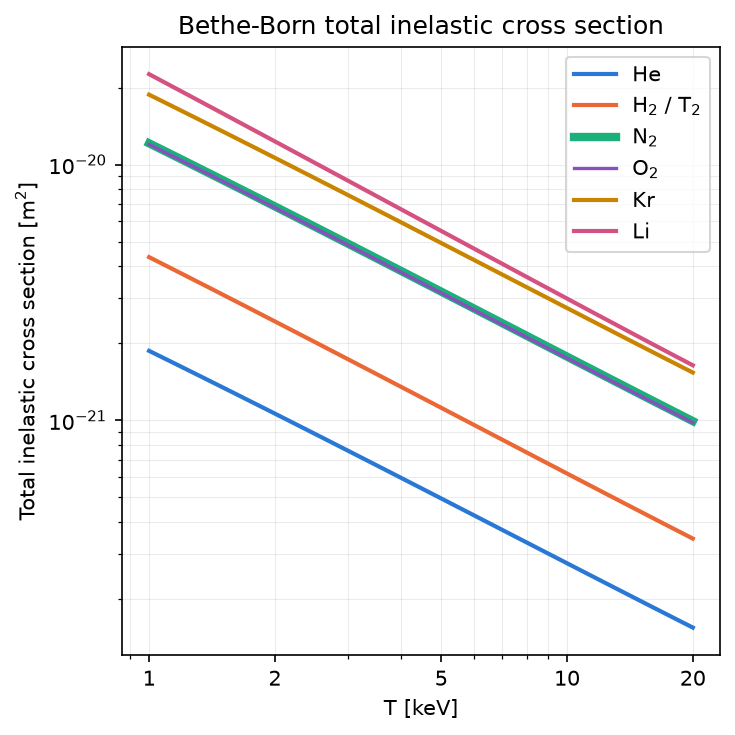

In [42]:

T = np.logspace(3, np.log10(2e4), 60)                  # 1 keV ... 20 keV
fig, ax = plt.subplots(figsize=(5, 5),dpi=150)
rows = []
for p in PARAMS:
    s = sigma_rel_a02(T, p.M2, p.C_nr) * A0_CM**2 * 1e-4     # units of 1e-16 cm^2
    rows.extend((p.species, p.variant, Ti, si) for Ti, si in zip(T, s))
    if not (is_primary(p)):
        continue

    # N2 and O2 nearly coincide: draw N2 wide
    lw = {"N$_2$": 4.0, "O$_2$": 1.6}.get(p.species, 2.0) if is_primary(p) else 1.6
    ax.plot(T / 1e3, s, color=COLORS[p.species], lw=lw, ls="-" if is_primary(p) else "--",
            zorder=3 if p.species == "O2" else 2, label=p.species)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("T [keV]")
ax.set_ylabel(r"Total inelastic cross section [m$^2$]")
ax.set_title("Bethe-Born total inelastic cross section")
ax.set_xticks([1, 2, 5, 10, 20]); ax.set_xticklabels(["1", "2", "5", "10", "20"])
ax.grid(True, which="both", alpha=0.25)
ax.legend(loc='upper right')

fig.tight_layout()
plt.savefig("Plots/TotalInelastic.png",dpi=150)

